> 🔑 **SOLUTIONS NOTEBOOK**: instructor / self-check copy. Try the problems in `../notebooks/` first!

# 🎛️ Lesson 07: Hyperparameter Tuning

**Time:** ~3 hours  **Prerequisites:** Lessons 03, 04 and 06

You now own powerful models with a dozen knobs each: learning rate, tree size, subsampling, regularisation… The defaults are decent; **tuned** settings are often 5–15% better. But a model with seven hyperparameters has *billions* of settings. How do we search *intelligently*?

> 💡 **Analogy: finding the best coffee shop in a new city.** *Grid search* = visit every street in a fixed pattern. *Random search* = visit random addresses. *Bayesian optimisation* = after each cup, update your mental map ("the good places cluster near the old market") and let that map decide where to try next, balancing "go where it's been good" with "explore where I know nothing".

### 🎯 Learning goals
1. Distinguish **parameters** (learned) from **hyperparameters** (chosen) and design a sensible **search space** (log scales!).
2. Run **grid** and **random** search, and explain *why random usually wins*.
3. Understand **successive halving** (spend little on bad candidates).
4. Explain **Bayesian optimisation**: surrogate model + acquisition function (**expected improvement**), and compute EI by hand.
5. Use **Optuna** (TPE sampler + pruning) on a real boosting model, read its diagnostics, and follow a **tuning playbook** for gradient boosting.
6. Avoid the traps: tuning on the test set, over-tuning to CV noise, wasting budget on unimportant knobs.

In [1]:
import sys; sys.path.append("../utils")          # lets us import the course helpers
from course_utils import *                       # load_housing(), check(), set_style(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt

set_style()
np.random.seed(SEED)
import optuna, lightgbm as lgb, xgboost as xgb
from scipy.stats import loguniform, randint, uniform, norm
from sklearn.model_selection import KFold, ParameterGrid, RandomizedSearchCV
from sklearn.experimental import enable_halving_search_cv      # halving search is still flagged 'experimental' in scikit-learn
from sklearn.model_selection import HalvingRandomSearchCV
from animations import bayesopt_animation, objective_1d, expected_improvement
optuna.logging.set_verbosity(optuna.logging.WARNING)            # keep the output tidy
import seaborn as sns

## 1 · Parameters vs. hyperparameters

| | **parameters** | **hyperparameters** |
|---|---|---|
| examples | tree split thresholds, leaf values, regression coefficients | learning rate, number of trees, `num_leaves`, `min_child_samples`, `subsample`, `reg_lambda` |
| who sets them | the **training algorithm** | **you** (before training) |
| how | optimisation on the training loss | search, guided by *validation* performance |

Every evaluation of a hyperparameter setting means **training a model** (and, with 5-fold CV, five of them). Tuning is therefore a **budget** problem: *given 30 or 100 evaluations, find the best setting.* Everything in this lesson is a different answer to that question.

### Our testbed
We tune **LightGBM** on the housing training set with 5-fold CV RMSE as the objective. The test set will be touched only at the very end.

*(To keep the lesson fast we pre-process once on the training set. The leakage from median-imputation and one-hot encoding is negligible here, but in production keep preprocessing inside a `Pipeline`, as in Lesson 06.)*

In [2]:
X_train, X_test, y_train, y_test = get_housing_split()
prep = make_preprocessor(X_train)
A_train, A_test = prep.fit_transform(X_train), prep.transform(X_test)
ytr, yte = y_train.values, y_test.values
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def cv_rmse(params):
    """THE objective: mean 5-fold CV RMSE of LightGBM with these hyperparameters (lower is better)."""
    scores = []
    for tr, va in kf.split(A_train):
        m = lgb.LGBMRegressor(random_state=0, verbose=-1, n_jobs=1, **params).fit(A_train[tr], ytr[tr])
        scores.append(rmse(ytr[va], m.predict(A_train[va])))
    return float(np.mean(scores))

def test_rmse(params):
    """Final check only: refit on ALL training data, score on the sealed test set."""
    return rmse(yte, lgb.LGBMRegressor(random_state=0, verbose=-1, n_jobs=1, **params).fit(A_train, ytr).predict(A_test))

with Timer() as t:
    default_cv = cv_rmse({})
print(f"LightGBM defaults:  CV RMSE = {default_cv:.1f}   (one evaluation = {t.seconds:.1f}s)   test RMSE = {test_rmse({}):.1f}")

LightGBM defaults:  CV RMSE = 130.3   (one evaluation = 0.2s)   test RMSE = 109.1


Our baseline: **CV RMSE ≈ 130** with LightGBM's defaults. (CV RMSE is higher than test RMSE here simply because the training set happens to contain more of the extreme "mansion" rows than the test set; another reminder that absolute numbers are noisy; we compare methods on the *same* objective.)

## 2 · Grid search

**Grid search** tries *every combination* from a hand-written list. Simple, exhaustive, parallel… and brutal:

| hyperparameters | values each | configurations | × 5-fold CV = model fits |
|---|---|---|---|
| 3 | 3 | 27 | 135 |
| 5 | 4 | 1,024 | 5,120 |
| 7 | 5 | 78,125 | 390,625 |

The cost grows **exponentially** with the number of hyperparameters (the "curse of dimensionality"). A 27-point grid is affordable, so let's see what it can do:

In [3]:
grid_space = {"learning_rate": [0.02, 0.05, 0.1], "num_leaves": [8, 16, 31], "n_estimators": [200, 400, 800]}
grid_points = list(ParameterGrid(grid_space))

with Timer() as t_grid:
    grid_scores = [cv_rmse({**p, "min_child_samples": 20}) for p in grid_points]
grid_df = pd.DataFrame(grid_points).assign(cv_rmse=grid_scores)
best_grid_params = grid_points[int(np.argmin(grid_scores))]          # a plain dict with proper int / float types

print(f"{len(grid_points)} configurations, {t_grid.seconds:.0f}s.   best CV RMSE = {min(grid_scores):.1f} with {best_grid_params}")

pivot = grid_df.groupby(["num_leaves", "learning_rate"])["cv_rmse"].min().unstack()
plt.figure(figsize=(5.8, 3.6)); sns.heatmap(pivot, annot=True, fmt=".0f", cmap="viridis_r", cbar=False)
plt.title("Grid: best CV RMSE for each (num_leaves, learning_rate)"); plt.show()

27 configurations, 20s.   best CV RMSE = 118.6 with {'learning_rate': 0.05, 'n_estimators': 800, 'num_leaves': 8}


The grid improved on the defaults (≈ 130 → ≈ 119): a real gain, and the heatmap shows the landscape: small trees (`num_leaves=8`) beat big ones on this small dataset.

But notice what a grid *can't* do: it tested only **three distinct values** of each hyperparameter. If the true sweet spot for `learning_rate` is 0.035, the grid will never see it.

## 3 · Random search: usually better than grid, with the same budget

Bergstra & Bengio (2012) made a simple, powerful observation: **in most problems only a few hyperparameters really matter**, and *which ones* varies by dataset. Consider two hyperparameters where only $x$ matters:

* A **3 × 3 grid** uses 9 evaluations but tests only **3 distinct values of $x$**.
* **9 random points** test **9 distinct values of $x$**: three times better coverage of what matters.

Let's see it, and then measure how often random beats the grid in a toy landscape where only $x$ matters:

In [4]:
def toy(x, y):                                          # a narrow peak in x; y barely matters
    return np.exp(-((x - 0.62) / 0.07) ** 2) + 0.15 * np.exp(-((y - 0.5) / 0.4) ** 2)

g = np.array([0.17, 0.5, 0.83])
gx, gy = np.meshgrid(g, g); gx, gy = gx.ravel(), gy.ravel()
rng = np.random.default_rng(3)
rx, ry = rng.random(9), rng.random(9)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
for ax, (px, py, title) in zip(axes, [(gx, gy, "Grid search: 9 points, 3 distinct x"), (rx, ry, "Random search: 9 points, 9 distinct x")]):
    ax.contourf(xx, yy, toy(xx, yy), levels=15, cmap="Greys", alpha=.5)
    ax.scatter(px, py, s=60, color=PALETTE["red"], edgecolor="white", zorder=3)
    for v in px: ax.plot([v, v], [-0.04, -0.01], color=PALETTE["red"], lw=3, clip_on=False)
    ax.set_title(title); ax.set_xlabel("important hyperparameter x"); ax.grid(False)
axes[0].set_ylabel("unimportant hyperparameter y")
plt.tight_layout(); plt.show()

wins = np.mean([toy(*np.random.default_rng(s).random((2, 9))).max() > toy(gx, gy).max() for s in range(2000)])
print(f"random search (9 points) found a better optimum than the 3x3 grid in {wins:.0%} of 2000 repetitions")

random search (9 points) found a better optimum than the 3x3 grid in 88% of 2000 repetitions

### Search spaces: use the right *scale*
Random search needs a **distribution** for each hyperparameter, and the distribution matters:

| hyperparameter | type | distribution | why |
|---|---|---|---|
| `learning_rate` | continuous, spans orders of magnitude | **log-uniform** (0.01 → 0.3) | 0.01 vs 0.02 matters as much as 0.1 vs 0.2; uniform sampling would waste 90% of draws above 0.03 |
| `reg_lambda`, `reg_alpha` | continuous, orders of magnitude | **log-uniform** (1e-3 → 30) | same |
| `num_leaves`, `max_depth`, `min_child_samples` | integer | uniform integer | |
| `subsample`, `colsample_bytree` | fraction in (0, 1] | uniform (0.5 → 1) | |
| `n_estimators` | integer | uniform integer: or **fix it and use early stopping** | it interacts strongly with `learning_rate` |

Now 30 random draws from a 7-dimensional space (same budget as the 27-point grid):

In [5]:
random_space = {
    "learning_rate": loguniform(0.01, 0.3), "num_leaves": randint(4, 64), "n_estimators": randint(100, 900),
    "min_child_samples": randint(5, 60), "subsample": uniform(0.5, 0.5), "colsample_bytree": uniform(0.4, 0.6),
    "reg_lambda": loguniform(1e-3, 30),
}
from sklearn.model_selection import ParameterSampler
random_points = list(ParameterSampler(random_space, n_iter=30, random_state=0))

with Timer() as t_rand:
    random_scores = [cv_rmse({**p, "subsample_freq": 1}) for p in random_points]
best_random = random_points[int(np.argmin(random_scores))]
print(f"30 random configurations, {t_rand.seconds:.0f}s.   best CV RMSE = {min(random_scores):.1f}")
print({k: (round(float(v), 4) if isinstance(v, float) else int(v)) for k, v in best_random.items()})

30 random configurations, 32s.   best CV RMSE = 119.0
{'colsample_bytree': 0.6209, 'learning_rate': 0.2593, 'min_child_samples': 20, 'n_estimators': 531, 'num_leaves': 4, 'reg_lambda': 24.0654, 'subsample': 0.8996}


### Successive halving: don't waste time on obviously bad candidates
Most random configurations are mediocre, yet we train every one to completion. **Successive halving** is a tournament:

1. Start with many candidates, each given a **small resource** (few trees, or a data subset).
2. Keep the best **1/factor** of them (e.g. the top third); give the survivors **factor× more resource**.
3. Repeat until one resource budget is fully spent.

Scikit-learn implements it as `HalvingRandomSearchCV`. Here the *resource* is the number of boosting rounds: weak candidates are eliminated after 50 trees instead of being trained to 800.

In [6]:
halving_space = {k: v for k, v in random_space.items() if k != "n_estimators"}
base = lgb.LGBMRegressor(random_state=0, verbose=-1, n_jobs=1, subsample_freq=1)

with Timer() as t_halv:
    halving = HalvingRandomSearchCV(base, halving_space, resource="n_estimators", max_resources=800, min_resources=50, factor=3,
                                    n_candidates=60, cv=kf, scoring="neg_root_mean_squared_error", random_state=0).fit(A_train, ytr)

print(f"started with 60 candidates, survivors per round: {halving.n_candidates_}   (resource per round: {halving.n_resources_} trees)")
print(f"best CV RMSE = {-halving.best_score_:.1f}   in {t_halv.seconds:.0f}s   (random search with 30 full evaluations took {t_rand.seconds:.0f}s)")

started with 60 candidates, survivors per round: [60, 20, 7]   (resource per round: [50, 150, 450] trees)
best CV RMSE = 123.5   in 29s   (random search with 30 full evaluations took 32s)


Halving examined **60** candidates in about the same wall-clock time random search spent on 30 (twice the coverage. But look at the catch: its winner (CV RMSE ≈ 123) is *worse* than random search's (≈ 119). Early-round scores can eliminate slow starters) a small learning rate always looks bad after only 50 trees, so don't use the number of trees as the resource when `learning_rate` is also being searched. Halving shines when the resource is something *neutral*, like the amount of training data.

## 4 · Bayesian optimisation: learn from every evaluation

Grid and random search are **memoryless**: evaluation #20 ignores everything learned in #1–#19. **Bayesian optimisation** (BO) keeps a model of the objective and uses it to choose the next point.

**The loop**
1. Evaluate a few initial points.
2. Fit a cheap **surrogate model** to all results so far. A classic choice is a **Gaussian process (GP)**, which gives, for every candidate $x$, a predicted mean $\mu(x)$ **and** an uncertainty $\sigma(x)$ (large where we have no data).
3. An **acquisition function** scores every candidate by how promising it is, balancing:
   * **exploitation**: low predicted loss $\mu(x)$,
   * **exploration**: high uncertainty $\sigma(x)$ (it *might* be great).
4. Evaluate the **maximiser of the acquisition function** (the real, expensive objective), add the result, go to 2.

### Expected improvement (EI)
Let $f^\*$ be the best loss so far (we are *minimising*). EI is the *expected amount by which a candidate beats $f^\*$*:

$$\text{EI}(x) = (f^\* - \mu - \xi)\,\Phi(Z) + \sigma\,\varphi(Z),\qquad Z=\frac{f^\* - \mu - \xi}{\sigma}$$

with $\Phi,\varphi$ the standard normal CDF/PDF and $\xi\ge 0$ a small exploration bonus. The first term rewards a **good mean**; the second rewards **uncertainty**.

### 🧪 Worked Example 7.1: EI by hand
Best loss so far $f^\*=0.60$. Candidate: $\mu=0.50$, $\sigma=0.20$ (take $\xi=0$).

$Z=(0.60-0.50)/0.20=0.5$; $\Phi(0.5)=0.6915$; $\varphi(0.5)=0.3521$.

$$\text{EI}=0.10\times0.6915 + 0.20\times0.3521 = 0.0692+0.0704=\mathbf{0.1396}.$$

Half of the EI comes from the second term: *even if the mean were exactly $f^\*$, the uncertainty alone would give positive EI*: that's the exploration pressure.

In [7]:
print("EI(mu=0.50, sigma=0.20, best=0.60) =", round(float(expected_improvement(0.50, 0.20, 0.60, xi=0.0)), 4))
print("same mean as the best (mu=0.60) but sigma=0.20 ->", round(float(expected_improvement(0.60, 0.20, 0.60, xi=0.0)), 4), "(positive purely from uncertainty)")
print("same mean, but sigma -> 0                      ->", round(float(expected_improvement(0.60, 1e-9, 0.60, xi=0.0)), 4), "(a known value can't improve)")

EI(mu=0.50, sigma=0.20, best=0.60) = 0.1396
same mean as the best (mu=0.60) but sigma=0.20 -> 0.0798 (positive purely from uncertainty)
same mean, but sigma -> 0                      -> 0.0 (a known value can't improve)


### Watch it work
Below, the dashed black line is an *unknown* expensive function we want to minimise. Blue = the GP surrogate (mean and ±2σ band); red dots = evaluations so far; green = expected improvement and the next point chosen (vertical line).
Notice how EI is high **both** near the current best (exploitation) **and** in wide-uncertainty regions (exploration), and how the surrogate sharpens around the minimum.

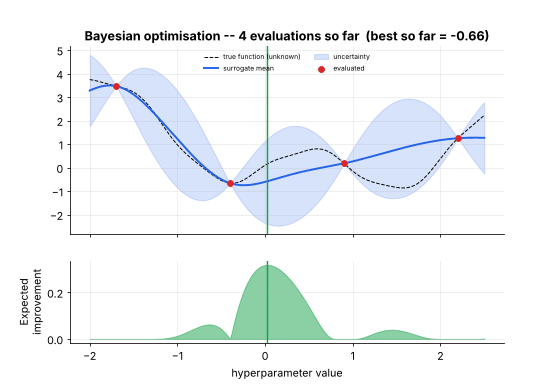

In [8]:
show_gif(bayesopt_animation())

### Does it actually beat random search? A fair fight
Let's pit a from-scratch BO (GP + EI) against random search on that 1-D function, 15 evaluations each, averaged over 20 different starting seeds. We track the **best value found so far** after each evaluation.

In [9]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel

lo, hi = -2.0, 2.5
cand = np.linspace(lo, hi, 400)
true_min = objective_1d(cand).min()

def run_random(seed, n=15):
    xs = np.random.default_rng(seed).uniform(lo, hi, n)
    return np.minimum.accumulate(objective_1d(xs))

def run_bo(seed, n=15, n_init=3):
    rng = np.random.default_rng(seed)
    xs = list(rng.uniform(lo, hi, n_init)); ys = [objective_1d(v) for v in xs]
    while len(xs) < n:
        gp = GaussianProcessRegressor(ConstantKernel(1.0, "fixed") * Matern(0.7, "fixed", nu=2.5), alpha=1e-4, normalize_y=True, optimizer=None)
        gp.fit(np.array(xs)[:, None], ys)
        mu, sd = gp.predict(cand[:, None], return_std=True)
        x_next = cand[np.argmax(expected_improvement(mu, sd, min(ys)))]               # acquisition: maximise EI
        xs.append(x_next); ys.append(objective_1d(x_next))
    return np.minimum.accumulate(ys)

rand_runs = np.array([run_random(s) for s in range(20)])
bo_runs = np.array([run_bo(s) for s in range(20)])

plt.figure(figsize=(8, 4.2))
for runs, label, color in [(rand_runs, "random search", PALETTE["gray"]), (bo_runs, "Bayesian optimisation (GP + EI)", PALETTE["blue"])]:
    m, s = (runs - true_min).mean(axis=0), (runs - true_min).std(axis=0)
    plt.plot(range(1, 16), m, "o-", color=color, label=label); plt.fill_between(range(1, 16), m - s, m + s, color=color, alpha=.15)
plt.yscale("log"); plt.xlabel("number of evaluations"); plt.ylabel("gap to the true minimum (log scale)")
plt.title("Bayesian optimisation closes in on the optimum much faster"); plt.legend(); plt.show()

After ~10 evaluations BO is typically **an order of magnitude closer** to the true minimum than random search. The price: BO's advantage shrinks in very high dimensions, with very noisy objectives, or when evaluations are cheap enough that you can afford thousands of random trials.

### TPE: the flavour inside Optuna and Hyperopt
GP-based BO scales poorly with many hyperparameters, categorical choices and conditional spaces. The **Tree-structured Parzen Estimator (TPE)** takes the opposite view: instead of modelling $p(\text{loss}\mid x)$ it models **$p(x\mid\text{good})$ and $p(x\mid\text{bad})$**: split past trials at a quantile of the loss, fit a density to each group: and proposes points where the ratio $p(x\mid\text{good})/p(x\mid\text{bad})$ is large. Cheap, handles mixed/conditional spaces, and it is **Optuna's default sampler**.

## 5 · Optuna in practice

Optuna's API is wonderfully small: write an **objective function** that *suggests* hyperparameters and *returns* the loss.

In [10]:
def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),       # log scale!
        num_leaves=trial.suggest_int("num_leaves", 4, 63),
        n_estimators=trial.suggest_int("n_estimators", 100, 900),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 60),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        subsample_freq=1,
    )
    return cv_rmse(params)

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
with Timer() as t_tpe:
    study.optimize(objective, n_trials=30)
print(f"30 TPE trials in {t_tpe.seconds:.0f}s.   best CV RMSE = {study.best_value:.1f}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in study.best_params.items()})

30 TPE trials in 24s.   best CV RMSE = 117.0
{'learning_rate': 0.0916, 'num_leaves': 5, 'n_estimators': 550, 'min_child_samples': 36, 'subsample': 0.6888, 'colsample_bytree': 0.486, 'reg_lambda': 0.0059}


### Equal budget, three strategies
The same 30-evaluation budget (27 for the grid), same objective. We plot the **best CV RMSE found so far** after each evaluation:

In [11]:
curves = {
    "Grid (27)":        np.minimum.accumulate(grid_scores),
    "Random (30)":      np.minimum.accumulate(random_scores),
    "Optuna TPE (30)":  np.minimum.accumulate([t.value for t in study.trials]),
}
plt.figure(figsize=(8.5, 4.3))
for (label, c), color in zip(curves.items(), [PALETTE["gray"], PALETTE["orange"], PALETTE["blue"]]):
    plt.plot(range(1, len(c) + 1), c, "o-", ms=3, label=f"{label}: {c[-1]:.1f}", color=color)
plt.axhline(default_cv, color="k", ls=":", label=f"defaults: {default_cv:.1f}")
plt.xlabel("evaluations"); plt.ylabel("best CV RMSE so far"); plt.title("Best-so-far vs. budget"); plt.legend(); plt.show()

### 🔎 Reading the race
* All three beat the defaults decisively; **TPE keeps improving steadily** while random search tends to find a good point early (or not) by luck.
* ⚠️ This is **one run**. Random and TPE are stochastic; a rigorous comparison repeats each with several seeds. Don't crown a winner from a single curve: the same discipline as Lesson 06!
* Notice how **small the differences are between sensible methods** compared with the gain from tuning at all. Don't agonise over the optimiser; spend your effort on a good search space and a reliable objective.

### Diagnostics: what did the search learn?
Optuna records every trial, so we can ask *which hyperparameters mattered* and *where the good region lies*.

In [12]:
import optuna.importance as oi
imp = pd.Series(oi.get_param_importances(study)).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
imp.plot.barh(ax=axes[0], color=PALETTE["blue"]); axes[0].set_title("Hyperparameter importance (fANOVA)")
df = study.trials_dataframe()
for ax, col in zip(axes[1:], ["params_num_leaves", "params_learning_rate"]):
    ax.scatter(df[col], df["value"], c=df["number"], cmap="viridis", s=45)
    ax.set_xlabel(col.replace("params_", "")); ax.set_ylabel("CV RMSE"); ax.set_title("Each dot = one trial (colour = order)")
axes[2].set_xscale("log")
plt.tight_layout(); plt.show()

The importance plot says where the objective is *sensitive*. In our run **`num_leaves` (tree complexity) clearly dominates**, followed by `n_estimators`, `reg_lambda` and `colsample_bytree`; `learning_rate` and `min_child_samples` matter little within the ranges we allowed. That's exactly the information you want for **narrowing the search space** in a second, finer round.
The scatter plots show the TPE sampler concentrating later (yellow) trials in the good region: *learning from evaluations*, which random search can't do.

### Pruning: stop bad trials early
Why finish all five folds of a trial that is clearly awful after two? Optuna's **pruners** compare a trial's *intermediate* results with earlier trials and stop it if it lags. We report the running mean RMSE after each fold:

In [13]:
def objective_pruned(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True), num_leaves=trial.suggest_int("num_leaves", 4, 63),
        n_estimators=trial.suggest_int("n_estimators", 100, 900), min_child_samples=trial.suggest_int("min_child_samples", 5, 60),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True), subsample_freq=1)
    scores = []
    for step, (tr, va) in enumerate(kf.split(A_train)):
        m = lgb.LGBMRegressor(random_state=0, verbose=-1, n_jobs=1, **params).fit(A_train[tr], ytr[tr])
        scores.append(rmse(ytr[va], m.predict(A_train[va])))
        trial.report(float(np.mean(scores)), step)             # tell Optuna how we're doing so far
        if trial.should_prune():                                # worse than the median of earlier trials at this step?
            raise optuna.TrialPruned()
    return float(np.mean(scores))

study_p = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0),
                              pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
with Timer() as t_pruned:
    study_p.optimize(objective_pruned, n_trials=30)

n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study_p.trials)
print(f"30 trials: {n_pruned} pruned early   |   time {t_pruned.seconds:.0f}s vs {t_tpe.seconds:.0f}s without pruning   |   best CV RMSE {study_p.best_value:.1f}")

30 trials: 13 pruned early   |   time 18s vs 24s without pruning   |   best CV RMSE 117.0


Pruning typically saves 20–50% of the compute at no loss in the final result: the savings grow with expensive models (deep learning, big GBMs). Early stopping *inside* each fit (Lesson 04) is a complementary trick.

## 6 · The verdict: score the tuned models on the sealed test set (once!)

Now, and only now, we touch the test set. Each strategy hands over its single best configuration; we refit on the full training set and evaluate.

In [14]:
final = pd.DataFrame([
    {"strategy": "Defaults",         "CV RMSE (inside search)": default_cv,           "test RMSE": test_rmse({})},
    {"strategy": "Grid (27)",        "CV RMSE (inside search)": min(grid_scores),     "test RMSE": test_rmse({**best_grid_params, "min_child_samples": 20})},
    {"strategy": "Random (30)",      "CV RMSE (inside search)": min(random_scores),   "test RMSE": test_rmse({**best_random, "subsample_freq": 1})},
    {"strategy": "Optuna TPE (30)",  "CV RMSE (inside search)": study.best_value,     "test RMSE": test_rmse({**study.best_params, "subsample_freq": 1})},
]).set_index("strategy")
final["n_estimators"] = [100, best_grid_params["n_estimators"], best_random["n_estimators"], study.best_params["n_estimators"]]
final.round(1)

,CV RMSE (inside search),test RMSE,n_estimators
strategy,,,
Defaults,130.3,109.1,100
Grid (27),118.6,106.1,800
Random (30),119.0,102.4,531
Optuna TPE (30),117.0,98.3,550


Two honest observations:

1. **Tuning helps**: every search beats the defaults on the test set too (≈ 109 → ≈ 98–106).
2. **The test RMSEs are noticeably lower than the CV RMSEs**: not because tuning cured anything, but because (as noted) the training folds contain more extreme houses. And remember Lesson 06: the CV score of the *winner* is optimistically biased by selection; only the test column is a fair estimate. Differences of a few RMSE points between the three searches are within the noise of a single run.

## 7 · A tuning playbook for gradient boosting

Don't search everything at once. A reliable order, from most to least important:

| step | what | how |
|---|---|---|
| 0 | **Fix the basics** | sensible objective/metric, clean CV (Lesson 06), early stopping on a validation fold |
| 1 | **Learning rate & rounds** | start with `learning_rate ≈ 0.05–0.1`; let **early stopping** pick `n_estimators` |
| 2 | **Tree complexity** | `max_depth` (3–8) or `num_leaves` (8–64); `min_child_samples` / `min_child_weight` (5–50): the biggest levers on over/under-fitting |
| 3 | **Randomisation** | `subsample` & `colsample_bytree` ∈ [0.5, 1] |
| 4 | **Regularisation** | `reg_lambda` (log-scale), `reg_alpha`, `gamma` |
| 5 | **Polish** | lower the learning rate 2–5× and raise rounds proportionally; average several seeds |

**Habits that separate pros from amateurs**
* **Log-scale** for rates and regularisers. **Narrow** the space after a first broad round (use importance plots).
* **Budget wisely:** 50–100 trials of a well-chosen space usually beats 1,000 of a sloppy one.
* **Seed everything** and, for the final decision, repeat with 2–3 seeds.
* **Never tune on the test set.** Every peek at the test set and every adjustment afterwards turns it into a *validation* set.
* **Record experiments** (Optuna can store studies in SQLite: `storage="sqlite:///study.db"`).
* **Stop when gains fall inside the noise** of your CV estimate (Lesson 06's standard error!). Tuning past that point is overfitting the validation folds.
* **Better features and cleaner data usually beat better hyperparameters.** Tune after you've done the modelling work, not instead of it.

### ✋ Check your understanding

Try to answer *out loud* before you open the answer. If you can't say it simply, you don't own it yet.

**Q1. Why is random search usually more efficient than grid search with the same number of trials?**

<details><summary>Show answer</summary>

In most problems only a few hyperparameters matter. A grid wastes evaluations by repeating the same few values of each important hyperparameter; random search tries a *new* value of every hyperparameter on each trial, so it explores the important dimensions much more densely.

</details>

**Q2. Why sample `learning_rate` log-uniformly?**

<details><summary>Show answer</summary>

Its effect is multiplicative: the difference between 0.01 and 0.02 matters as much as between 0.1 and 0.2. Uniform sampling on [0.01, 0.3] would place ~90% of the draws above 0.04 and barely explore the small-rate region where the best models often live.

</details>

**Q3. In Bayesian optimisation, what does the acquisition function trade off, and what happens if you only exploit?**

<details><summary>Show answer</summary>

It trades **exploitation** (low predicted loss) against **exploration** (high uncertainty). A purely exploiting search keeps sampling near the current best, can get stuck in a local optimum, and never discovers better regions it hasn't visited.

</details>

**Q4. A candidate has predicted mean equal to the current best and σ = 0. What is its expected improvement, and why?**

<details><summary>Show answer</summary>

**Zero.** EI = σ·φ(0) when μ = f*; with σ = 0 we are certain the value equals f* so it cannot improve. EI is positive for a point with the same mean only if there is uncertainty (the point might be better).

</details>

**Q5. You tuned with 5-fold CV and your best CV RMSE is 118. Why shouldn't you report 118 as your expected production error?**

<details><summary>Show answer</summary>

Selecting the best of many configurations on the same folds biases the score optimistically (selection bias), and CV folds are noisy. Report the performance on a held-out **test set** touched once (or use nested CV for small data).

</details>

## 8 · Problems

Variables available: `A_train, A_test, ytr, yte`, `kf`, `cv_rmse`, `test_rmse`, `rmse`, `expected_improvement`, `random_space`, `study`.

### 🧩 Problem 07.1 ⭐: Count the cost

A colleague proposes a grid search over **5 hyperparameters with 4 values each**, using **5-fold CV**.

* `n_fits_grid`: how many models get trained in total?
* A random search with **60 configurations** and the same 5-fold CV → `n_fits_random`
* In a 2-D grid with **5 values per axis**, how many *distinct values of one hyperparameter* are tested → `distinct_grid`; and for **25 random points** (almost surely) → `distinct_random`?

<details><summary>💡 Hint 1</summary>

Grid configurations = 4**5.

</details>

<details><summary>💡 Hint 2</summary>

Each configuration costs 5 fits (one per fold).

</details>

<details><summary>💡 Hint 3</summary>

A 5×5 grid uses 25 points but only 5 distinct values on each axis; 25 random draws give 25 distinct values.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [15]:
n_fits_grid = (4 ** 5) * 5
n_fits_random = 60 * 5
distinct_grid = 5
distinct_random = 25

# ---- self-check ----
check("07.1", lambda: (n_fits_grid, n_fits_random, distinct_grid, distinct_random) == (5120, 300, 5, 25),
      "4**5 = 1024 configurations × 5 folds = 5120; random: 60 × 5 = 300.", needs=[n_fits_grid, n_fits_random, distinct_grid, distinct_random])

✅ 07.1: correct -- nice work!


**✅ Solution walk-through (Problem 07.1)**

The grid needs 17× more fits than the random search (5,120 vs 300), yet tests only 4 values per hyperparameter, whereas the random search tests 60 distinct values of each.

### 🧩 Problem 07.2 ⭐⭐: Design a random-search space

Build `param_dist`: a dict of distributions for LightGBM, and run a `RandomizedSearchCV` over it:

* `learning_rate`: **log-uniform** between 0.005 and 0.3
* `num_leaves`: integers 4 to 63
* `min_child_samples`: integers 5 to 59
* `reg_lambda`: **log-uniform** between 1e-3 and 30

Then: `rs = RandomizedSearchCV(lgb.LGBMRegressor(n_estimators=300, random_state=0, verbose=-1, n_jobs=1), param_dist, n_iter=15, cv=3, scoring="neg_root_mean_squared_error", random_state=0)`
and fit it on `(A_train, ytr)`.

<details><summary>💡 Hint 1</summary>

`loguniform(a, b)` and `randint(lo, hi_exclusive)` come from `scipy.stats` (already imported).

</details>

<details><summary>💡 Hint 2</summary>

Remember `randint(4, 64)` yields 4..63 (the upper bound is *exclusive*).

</details>

<details><summary>💡 Hint 3</summary>

After building `rs`, call `rs.fit(A_train, ytr)`; `rs.best_params_` and `rs.cv_results_` become available.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [16]:
param_dist = {
    "learning_rate": loguniform(0.005, 0.3),
    "num_leaves": randint(4, 64),
    "min_child_samples": randint(5, 60),
    "reg_lambda": loguniform(1e-3, 30),
}
rs = RandomizedSearchCV(lgb.LGBMRegressor(n_estimators=300, random_state=0, verbose=-1, n_jobs=1), param_dist, n_iter=15, cv=3,
                        scoring="neg_root_mean_squared_error", random_state=0)
rs.fit(A_train, ytr)

# ---- self-check ----
def _ok():
    draws = param_dist["learning_rate"].rvs(2000, random_state=0)
    reg = param_dist["reg_lambda"].rvs(2000, random_state=0)
    return (isinstance(rs, RandomizedSearchCV) and len(rs.cv_results_["params"]) == 15
            and np.log10(draws.max() / draws.min()) > 1.4 and np.log10(reg.max() / reg.min()) > 3
            and 4 <= rs.best_params_["num_leaves"] <= 63 and np.median(draws) < 0.1)
check("07.2", _ok, "learning_rate and reg_lambda need log-uniform distributions (median of learning_rate draws far below the arithmetic midpoint); fit 15 iterations.",
      needs=[param_dist, rs])

✅ 07.2: correct -- nice work!


**✅ Solution walk-through (Problem 07.2)**

With `loguniform`, half of all learning-rate draws fall below ≈ 0.04 (the geometric midpoint) rather than 0.15 (the arithmetic one). The best configuration found typically has a small-to-moderate learning rate and fewer leaves: consistent with our grid and Optuna results.

### 🧩 Problem 07.3 ⭐⭐: Exploration beats exploitation (sometimes)

Implement `ei(mu, sigma, best, xi=0.0)`: expected improvement for **minimisation**: using `norm.cdf` / `norm.pdf`; return `0.0` when `sigma == 0`.

Then compare two candidates, with current best loss `best = 0.50`:
* **A:** μ = 0.45, σ = 0.01 (almost certainly a small improvement)
* **B:** μ = 0.60, σ = 0.30 (probably worse, but very uncertain)

Store `ei_A`, `ei_B`, and `pick` = `"A"` or `"B"`: the candidate EI would evaluate next.

<details><summary>💡 Hint 1</summary>

`z = (best - mu - xi) / sigma`; `ei = (best - mu - xi) * norm.cdf(z) + sigma * norm.pdf(z)`.

</details>

<details><summary>💡 Hint 2</summary>

Guard against division by zero: `if sigma <= 0: return 0.0`.

</details>

<details><summary>💡 Hint 3</summary>

Expect `ei_A ≈ 0.050` and `ei_B ≈ 0.076`, so B wins: exploration beats a tiny sure gain.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [17]:
def ei(mu, sigma, best, xi=0.0):
    if sigma <= 0:
        return 0.0
    z = (best - mu - xi) / sigma
    return (best - mu - xi) * norm.cdf(z) + sigma * norm.pdf(z)

ei_A = ei(0.45, 0.01, 0.50)
ei_B = ei(0.60, 0.30, 0.50)
pick = "A" if ei_A > ei_B else "B"

# ---- self-check ----
check("07.3", lambda: abs(ei(0.5, 0.2, 0.6) - 0.1396) < 5e-4 and ei(0.5, 0.0, 0.6) == 0.0 and abs(ei_A - 0.0500) < 2e-3
      and abs(ei_B - 0.0763) < 2e-3 and pick == "B", "Check against Worked Example 7.1: ei(0.5, 0.2, 0.6) ≈ 0.1396.",
      needs=[ei_A, ei_B, pick])

✅ 07.3: correct -- nice work!


**✅ Solution walk-through (Problem 07.3)**

A offers a near-certain improvement of ≈ 0.05; B has a 37% chance of being better *and*, when it is, by a lot. EI averages over those outcomes (0.076 > 0.050), so BO explores B first. This is the mechanism that lets BO escape local optima.

In [18]:
# reference numbers for the next problem: XGBoost with default settings on the same data
default_xgb_rmse = rmse(yte, xgb.XGBRegressor(random_state=0).fit(A_train, ytr).predict(A_test))
print(f"default XGBoost test RMSE: {default_xgb_rmse:.1f}")

default XGBoost test RMSE: 110.7


### 🧩 Problem 07.4 ⭐⭐⭐: Tune XGBoost with Optuna

Write an Optuna `objective(trial)` for **XGBoost** that returns the **3-fold CV RMSE** (`KFold(3, shuffle=True, random_state=SEED)`) on `(A_train, ytr)`, searching:

`learning_rate` (log, 0.01–0.3), `max_depth` (2–8), `n_estimators` (100–600), `min_child_weight` (1–20), `subsample` (0.5–1.0), `colsample_bytree` (0.4–1.0), `reg_lambda` (log, 1e-3–30).

Run **25 trials** with `TPESampler(seed=0)` → `study_x`. Refit XGBoost with `study_x.best_params` on all training data and store its **test RMSE** in `tuned_test_rmse`.

<details><summary>💡 Hint 1</summary>

Inside the objective: `params = dict(learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True), max_depth=trial.suggest_int('max_depth', 2, 8), ...)`.

</details>

<details><summary>💡 Hint 2</summary>

Loop over `KFold(3, ...).split(A_train)`, fit `xgb.XGBRegressor(random_state=0, **params)`, collect RMSEs, return their mean.

</details>

<details><summary>💡 Hint 3</summary>

`study_x = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=0)); study_x.optimize(objective, n_trials=25)`.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [19]:
kf3 = KFold(3, shuffle=True, random_state=SEED)

def objective_x(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True), max_depth=trial.suggest_int("max_depth", 2, 8),
        n_estimators=trial.suggest_int("n_estimators", 100, 600), min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True))
    scores = [rmse(ytr[va], xgb.XGBRegressor(random_state=0, **params).fit(A_train[tr], ytr[tr]).predict(A_train[va])) for tr, va in kf3.split(A_train)]
    return float(np.mean(scores))

study_x = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
study_x.optimize(objective_x, n_trials=25)
best_x = xgb.XGBRegressor(random_state=0, **study_x.best_params).fit(A_train, ytr)
tuned_test_rmse = rmse(yte, best_x.predict(A_test))
print(f"tuned XGBoost test RMSE: {tuned_test_rmse:.1f}   (defaults: {default_xgb_rmse:.1f});   best params: {study_x.best_params}")

# ---- self-check ----
check("07.4", lambda: len(study_x.trials) == 25 and abs(study_x.best_value - min(t.value for t in study_x.trials)) < 1e-12
      and set(study_x.best_params) == {"learning_rate", "max_depth", "n_estimators", "min_child_weight", "subsample", "colsample_bytree", "reg_lambda"}
      and tuned_test_rmse < 115,
      "25 completed trials over exactly those 7 hyperparameters; the tuned test RMSE should be below 115.", needs=[study_x, tuned_test_rmse])

tuned XGBoost test RMSE: 97.3   (defaults: 110.7);   best params: {'learning_rate': 0.04278130823639746, 'max_depth': 3, 'n_estimators': 581, 'min_child_weight': 4, 'subsample': 0.6592254556387149, 'colsample_bytree': 0.5201715018661046, 'reg_lambda': 6.991704104849108}
✅ 07.4: correct -- nice work!


**✅ Solution walk-through (Problem 07.4)**

In our run tuning cut the test RMSE from ≈ 110.7 (defaults) to ≈ 97.3 (a 12% gain from 25 trials. The winning configuration is *shallow* (depth 3), subsampled (≈ 0.66 of rows, ≈ 0.52 of columns), moderately regularised and uses a smallish learning rate with ≈ 580 trees: on 2,400 rows, simple and well-regularised beats deep and greedy. A fresh study with different seeds can land a few points either way) with so few trials the *search itself* is noisy, so average over seeds before declaring a winner. Check `optuna.importance.get_param_importances(study_x)` to see which knobs mattered.

In [20]:
scoreboard()

Scoreboard: 4 solved, 0 to fix, 0 not attempted
   ✅ 07.1
   ✅ 07.2
   ✅ 07.3
   ✅ 07.4


## 🏁 Recap

* **Hyperparameters** are chosen, not learned; every evaluation costs a (cross-validated) training run: tuning is a *budget* problem.
* **Grid search** is exponential and covers few distinct values; **random search** (log-scales for rates!) is the dependable default.
* **Successive halving** spends little on weak candidates; **pruning** stops bad trials early.
* **Bayesian optimisation** keeps a surrogate (GP / TPE) and an **acquisition function** (EI = $(f^*-\mu)\Phi(Z)+\sigma\varphi(Z)$) that balances exploitation and exploration: it converges much faster on expensive objectives.
* **Optuna** makes this a 15-line recipe; use its importance plots to *narrow* the space.
* Tune in a sensible **order** (rate & rounds → tree complexity → randomisation → regularisation), never tune on the test set, and stop when gains vanish inside the CV noise.

### ➡️ Next up: **Lesson 08: Model Interpretability**
We now have an accurate, tuned black box. *Why* does it predict what it predicts? Feature importance (and why the built-in kind lies), permutation importance, and **SHAP**: with Shapley values computed by brute force so you truly understand them.